In [22]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### General imports

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### Plot of traces from .csv

All traces in this notebook are obtained with RMS detector

In [24]:
def plot_spectrum_traces(csv_filepath: str):
    """
    Reads a long-format CSV generated by sweep_grid_averaged_trace 
    and plots the spectrum traces for each configuration.
    """
    print(f"Loading data from {csv_filepath}...")
    df = pd.read_csv(csv_filepath)

    # Filter out rows where instrument connection failed
    df = df[df['level_dbm'] != 'ERROR'].copy()

    # Ensure measurement columns are numeric
    df['freq_hz'] = pd.to_numeric(df['freq_hz'])
    df['level_dbm'] = pd.to_numeric(df['level_dbm'])

    # Group by the configuration parameters to isolate individual traces
    group_cols = ['cfg_idx', 'set_current', 'set_c1', 'set_c2', 'set_r1']
    
    plt.figure(figsize=(12, 7))

    for name, group in df.groupby(group_cols):
        cfg_idx, curr, c1, c2, r1 = name
        label = f"Base {cfg_idx} | Curr:{curr} C1:{c1} C2:{c2} R1:{r1}"
        
        # Sort by frequency to ensure the line plots sequentially
        group = group.sort_values('freq_hz')
        
        # Scale frequency to MHz for a cleaner X-axis
        plt.plot(group['freq_hz'] / 1e6, group['level_dbm'], label=label, linewidth=1.5)

    plt.title('PLL Averaged Spectrum Traces')
    plt.xlabel('Frequency (MHz)')
    plt.ylabel('Power Level (dBm)')
    plt.grid(True, which="both", linestyle="--", alpha=0.6)
    
    # Place legend outside the plot area to avoid covering the traces
    plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize='small')
    plt.tight_layout()
    plt.show()

### Bumpy profiles at PLL output for different VCO configs

Clock reference frequency is 18.75 MHz

In [ ]:
CSV_DIR = Path.cwd().resolve().parents[2] / "results" / "spectrum"  # notebook lives in sw/tools/notebooks/
TRACES_375_CSV = "averaged_trace_grid_20261007_163713.csv"
TRACES_75_CSV = "averaged_trace_grid_20261007_163846.csv"  
filepath_375 = CSV_DIR / TRACES_375_CSV
filepath_75 = CSV_DIR / TRACES_75_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261007_163713.csv...


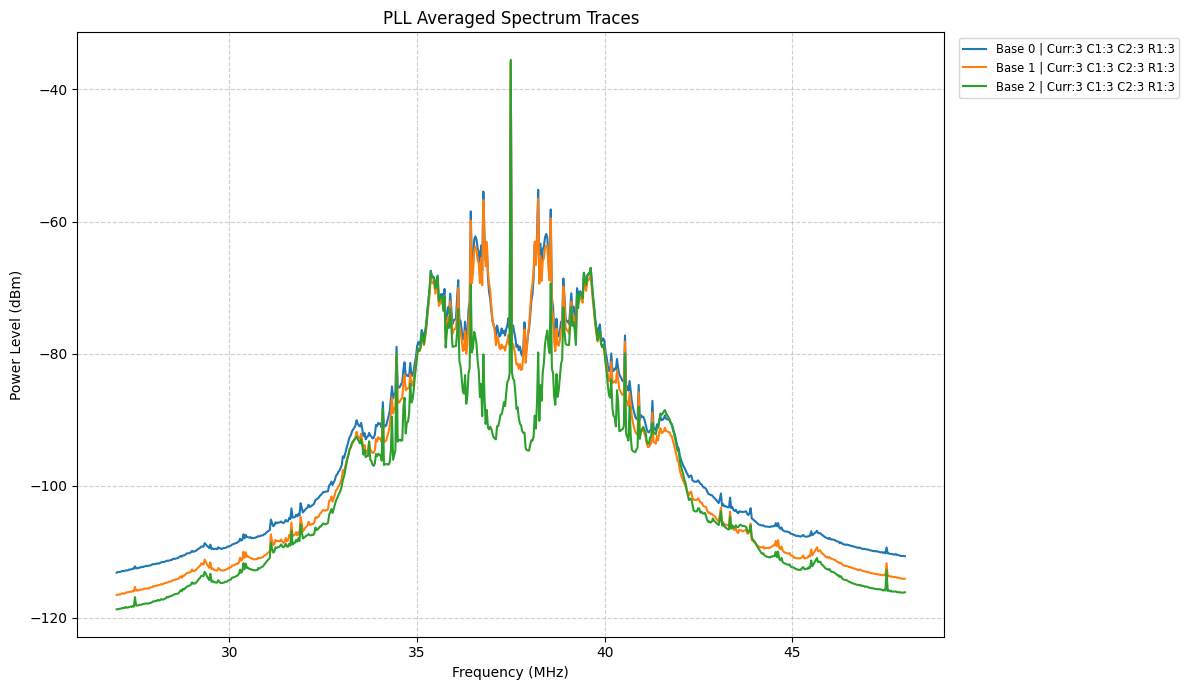

In [26]:
plot_spectrum_traces(filepath_375)

The profile repeats itself at different division factors

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261007_163846.csv...


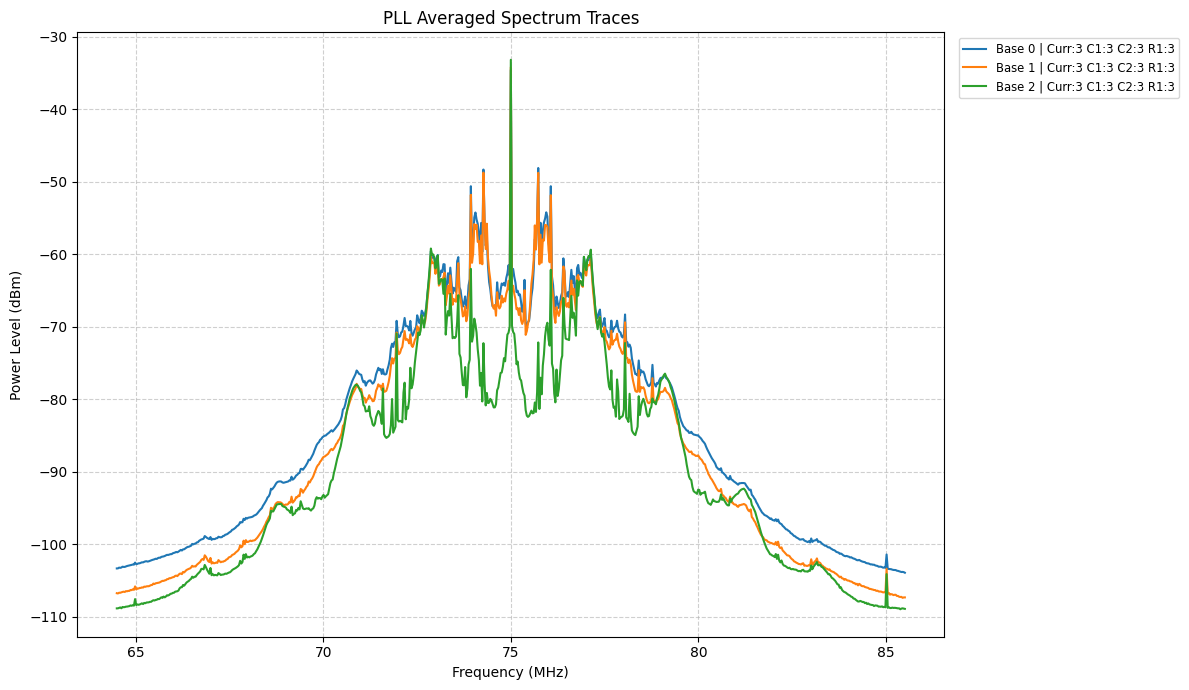

In [27]:
plot_spectrum_traces(filepath_75)

### Maximum bandwidth setting

Same plots as before but maximizing filter bandwidth (lowest phase noise)

In [28]:
TRACES_375_CSV = "averaged_trace_grid_20261007_162911.csv"
TRACES_75_CSV = "averaged_trace_grid_20261007_163044.csv"  
filepath_375 = CSV_DIR / TRACES_375_CSV
filepath_75 = CSV_DIR / TRACES_75_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261007_162911.csv...


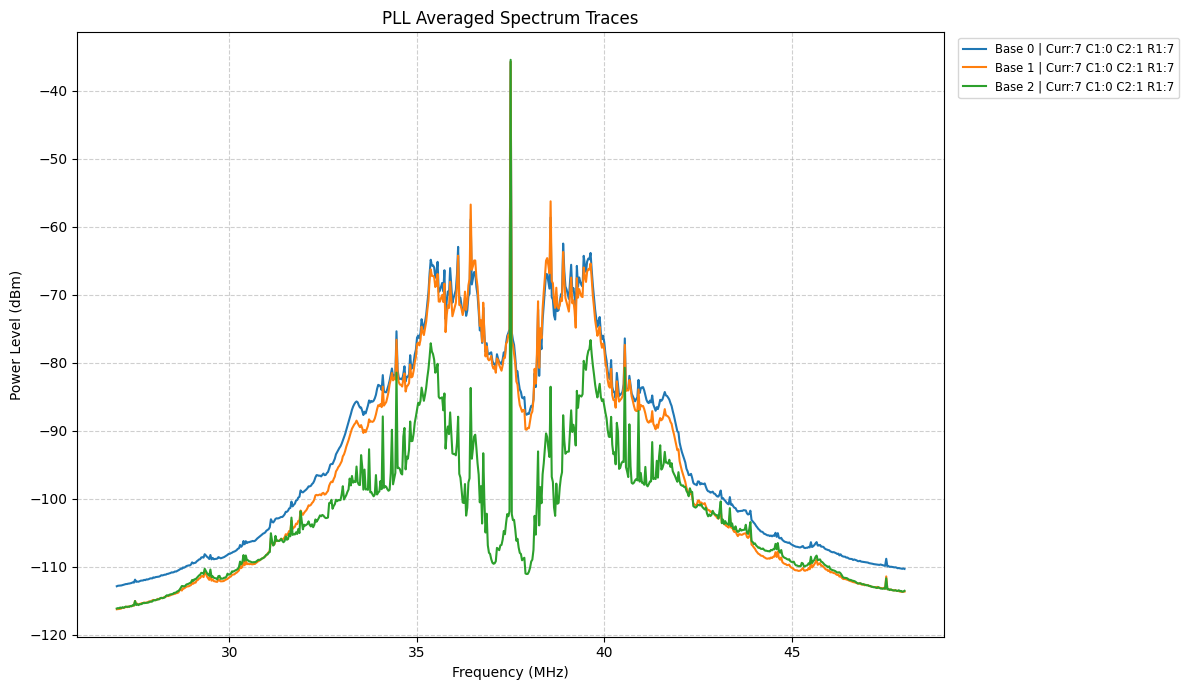

In [29]:
plot_spectrum_traces(filepath_375)

It is curious that for some settings the phase noise profile is assymetric. 
This is entirely dependent of the filter settings, since the VCO is unchanged since the previous traces

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261007_163044.csv...


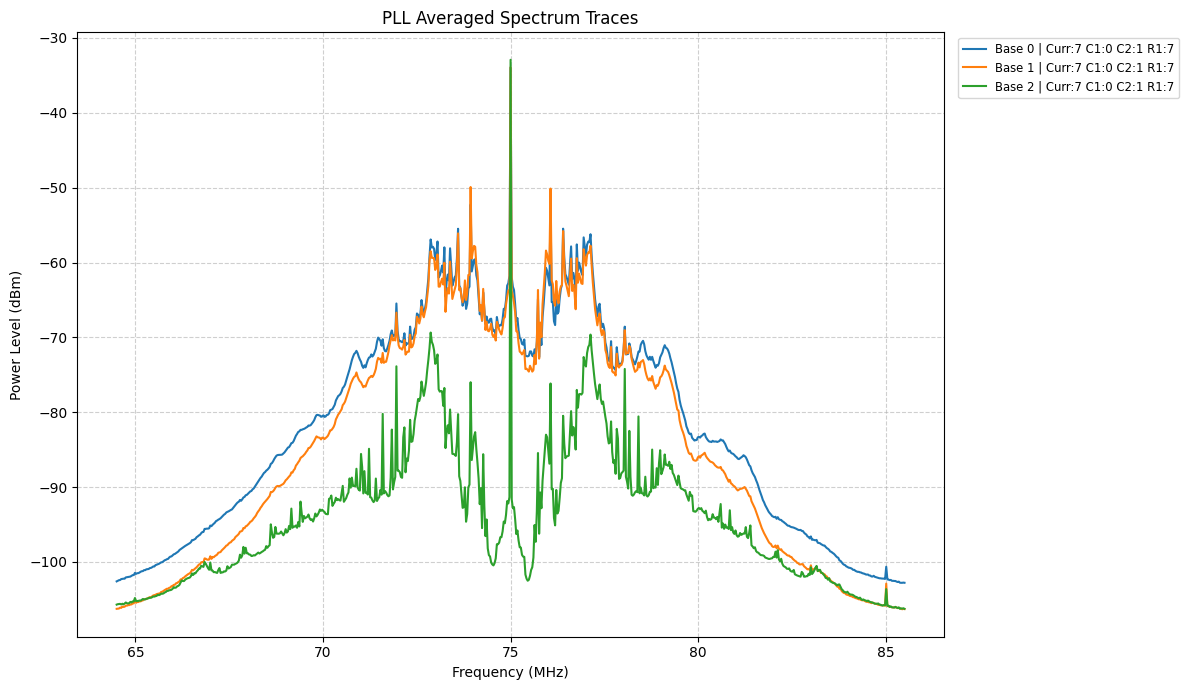

In [30]:
plot_spectrum_traces(filepath_75)

### Lowest jitter setting


Clock reference frequency is 37.5 MHz

In [31]:
TRACES_375_CSV = "averaged_trace_grid_20261007_165729.csv"
TRACES_75_CSV = "averaged_trace_grid_20261007_165802.csv"  
filepath_375 = CSV_DIR / TRACES_375_CSV
filepath_75 = CSV_DIR / TRACES_75_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261007_165729.csv...


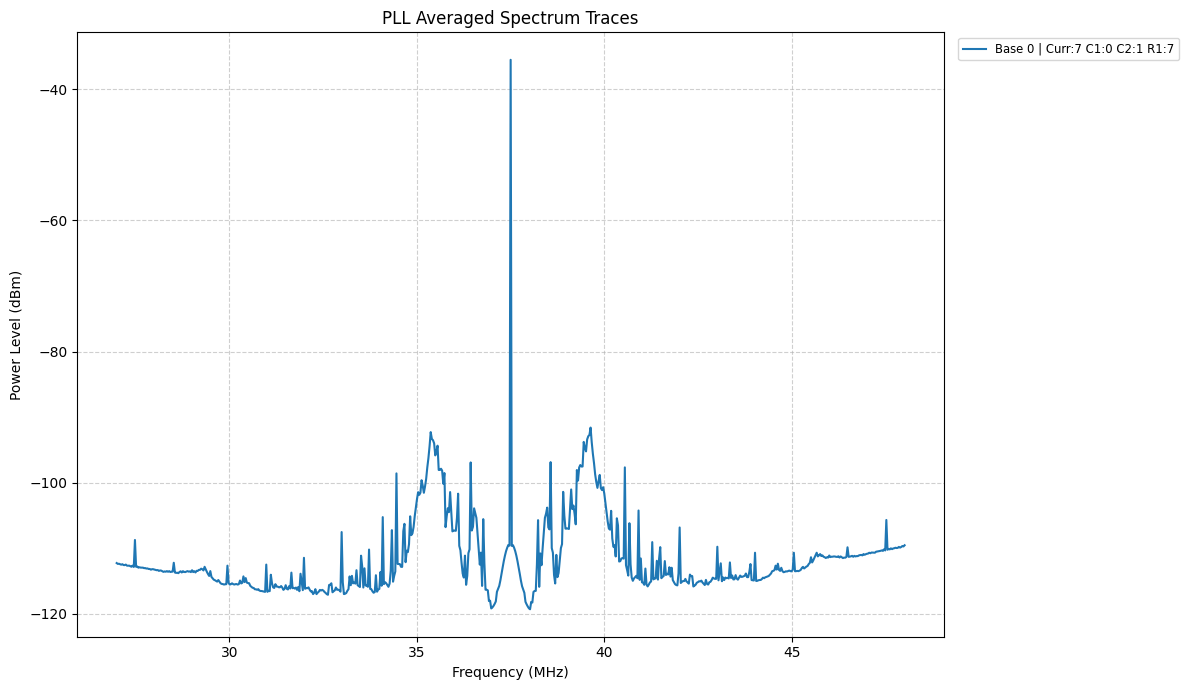

In [32]:
plot_spectrum_traces(filepath_375)

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261007_165802.csv...


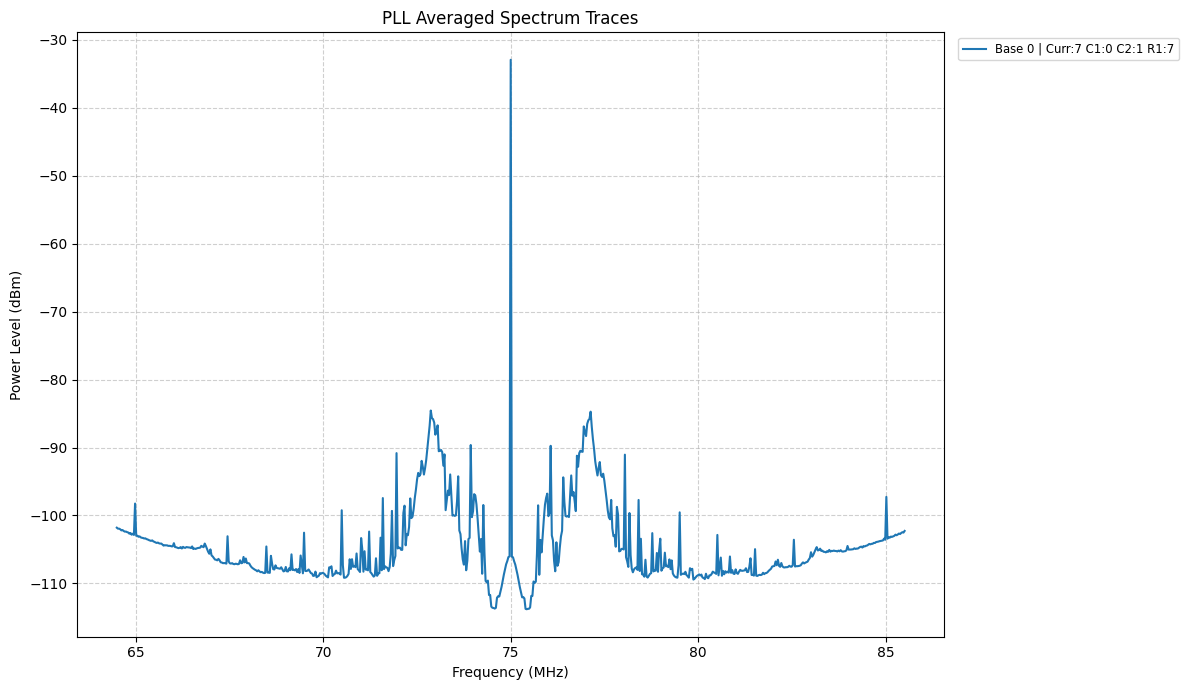

In [33]:
plot_spectrum_traces(filepath_75)

### Influence of $C_1$/$C_2$

Essentially, changing these 2 moves both pole-zero (lower C -> higher pole/BW -> more phase noise attenuation)

**Question**: Is the peak related to peaking at the bandwidth?

In [34]:
TRACES_75_CSV = "averaged_trace_grid_20261008_111255.csv"
filepath_75 = CSV_DIR / TRACES_75_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261008_111255.csv...


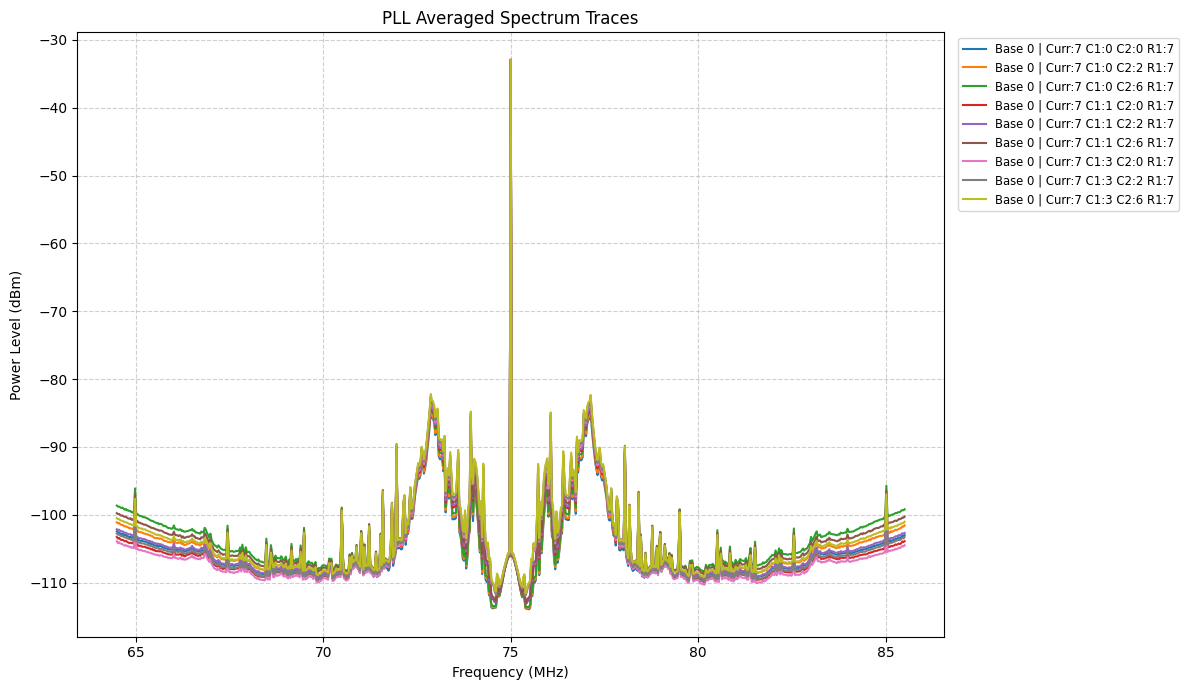

In [35]:
plot_spectrum_traces(filepath_75)

### Sweeping $R_1$

Changing $R_1$ would also move pole-zero at the same time.

In this case, the loop filter dynamics are clearly affecting the second bump (maybe a resonant peak), but having no impact on the first one.

In [36]:
TRACES_75_CSV = "averaged_trace_grid_20261008_144024.csv"
filepath_75 = CSV_DIR / TRACES_75_CSV

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261008_144024.csv...


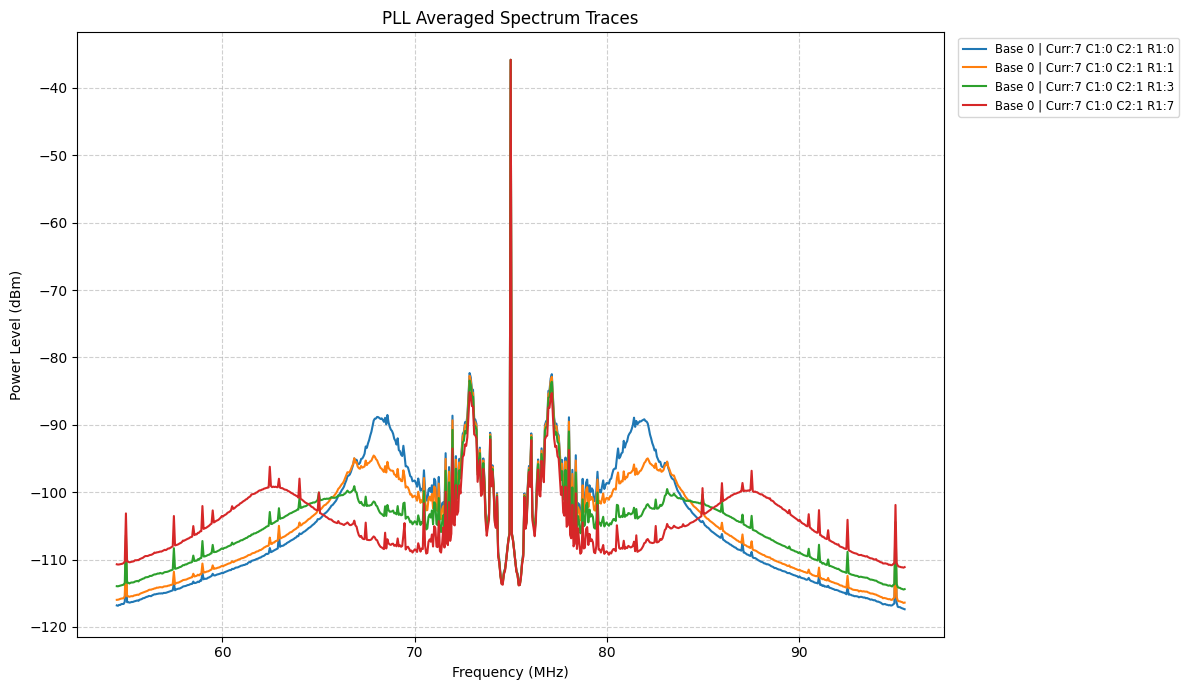

In [37]:
plot_spectrum_traces(filepath_75)

### Sweeping different parameters in the curves with multiple peaks (coarse 1 setting)

#### Sweep $R_1$

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261009_120341.csv...


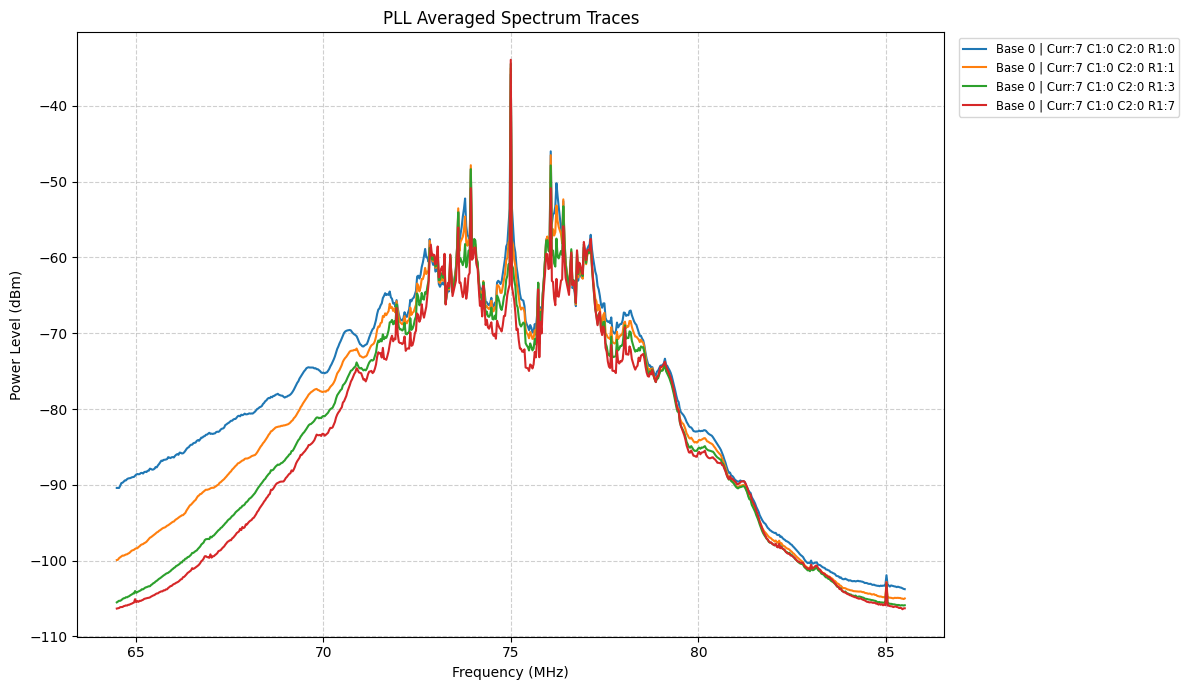

In [38]:
TRACES_75_CSV = "averaged_trace_grid_20261009_120341.csv"
filepath_75 = CSV_DIR / TRACES_75_CSV
plot_spectrum_traces(filepath_75)

Noticeable asymmetry (perhaps error in the acquistion?)

#### Sweep $C_1$

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261009_120545.csv...


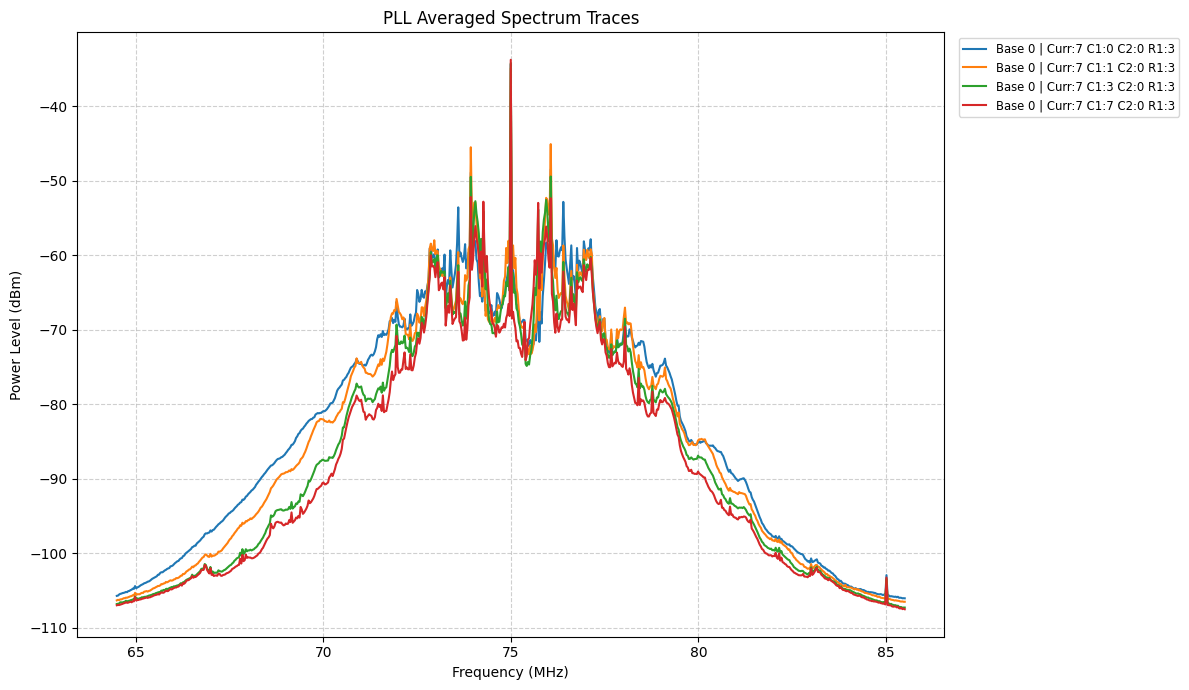

In [39]:
TRACES_75_CSV = "averaged_trace_grid_20261009_120545.csv"
filepath_75 = CSV_DIR / TRACES_75_CSV
plot_spectrum_traces(filepath_75)

#### Sweep $C_2$

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261009_120749.csv...


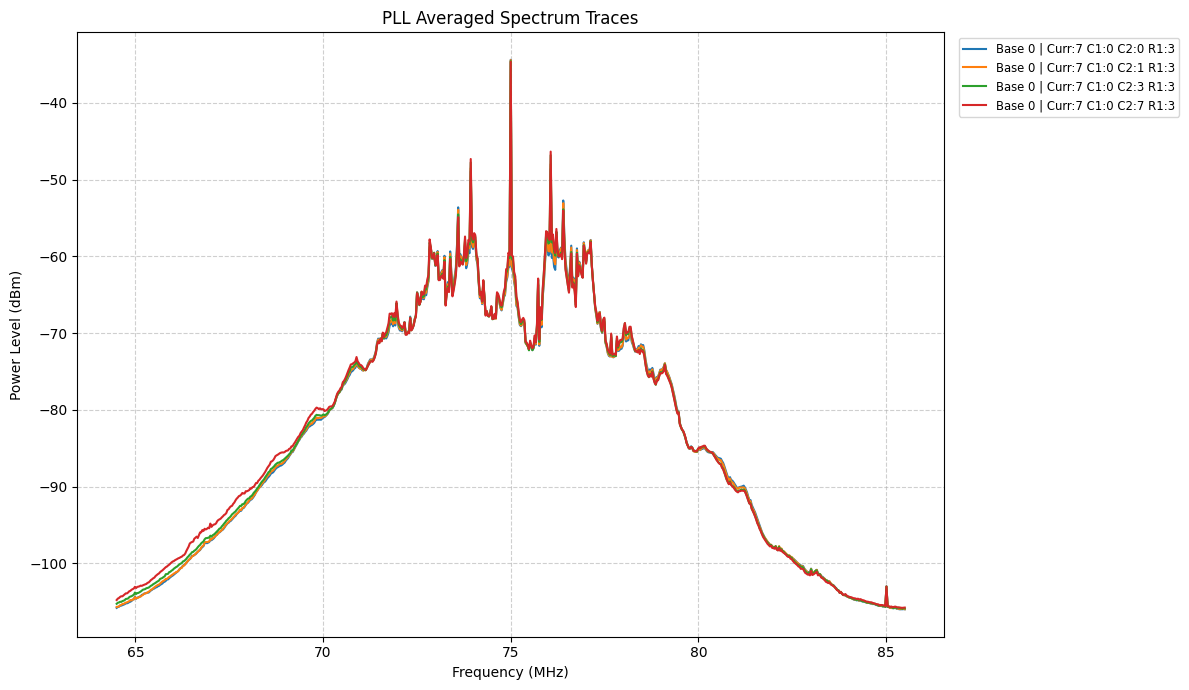

In [40]:
TRACES_75_CSV = "averaged_trace_grid_20261009_120749.csv"
filepath_75 = CSV_DIR / TRACES_75_CSV
plot_spectrum_traces(filepath_75)

#### Sweep $I_{CP}$

Loading data from /users/micas/iramrezl/projects/lagd-meas/results/spectrum/averaged_trace_grid_20261009_120953.csv...


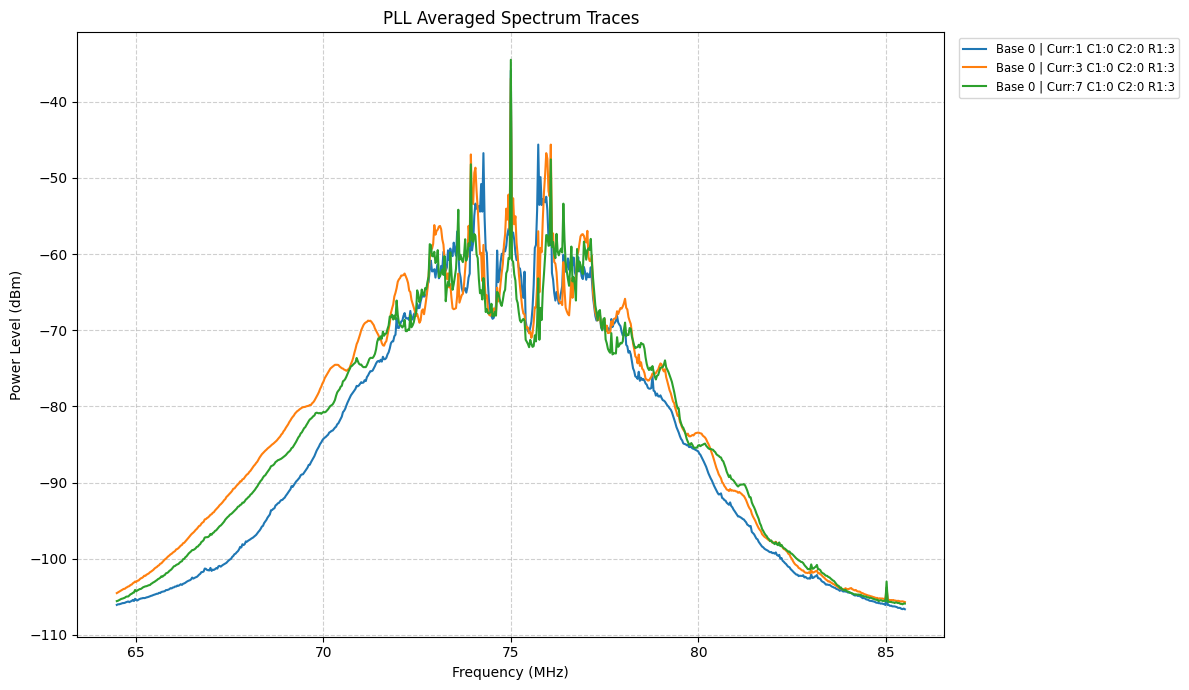

In [41]:
TRACES_75_CSV = "averaged_trace_grid_20261009_120953.csv"
filepath_75 = CSV_DIR / TRACES_75_CSV
plot_spectrum_traces(filepath_75)